In [1]:
import pandas as pd
import numpy as np

# Import data

In [7]:
path = "../data/all_MGS.csv"

In [11]:
df = pd.read_csv(path)
df = df.iloc[:, 2:]

In [16]:
df.head()

,image_id,n_foci,area,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity,sample,experiment
0,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,268,6.0,2.763953,0.848528,0.875000,5.414214,45.222221,50.0,40.0,WT,20226
1,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,277,5.0,2.523133,0.848911,0.903226,5.207107,25.250000,29.0,22.0,WT,20226
2,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,320,5.0,2.523133,0.867934,1.000000,4.621320,31.743421,36.0,28.0,WT,20226
3,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,341,5.0,2.523133,0.834131,1.000000,5.207107,45.625000,51.0,40.0,WT,20226
4,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,336,4.0,2.256758,0.870250,1.000000,3.414214,34.571430,38.0,31.0,WT,20226


In [14]:
# Clean data
df.columns = df.columns.str.strip().str.lower()
df.iloc[:, 1:9] = df.iloc[:, 1:9].apply(pd.to_numeric, errors="coerce")
df = df.dropna()

print("Number of cells is:", df.shape[0])

Number of cells is: 516


# UMAP

In [17]:
import umap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

features = [
    "n_foci",
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
    "min_intensity",
]

# Select features
X = df[features]

# Standardize
X_scaled = StandardScaler().fit_transform(X)

# UMAP
reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="euclidean",
    random_state=42
)

X_umap = reducer.fit_transform(X_scaled)

# Create dataframe
umap_df = df.copy()

umap_df["UMAP1"] = X_umap[:, 0]
umap_df["UMAP2"] = X_umap[:, 1]

/home/lopatushka/miniconda3/envs/imagej/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/lopatushka/miniconda3/envs/imagej/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


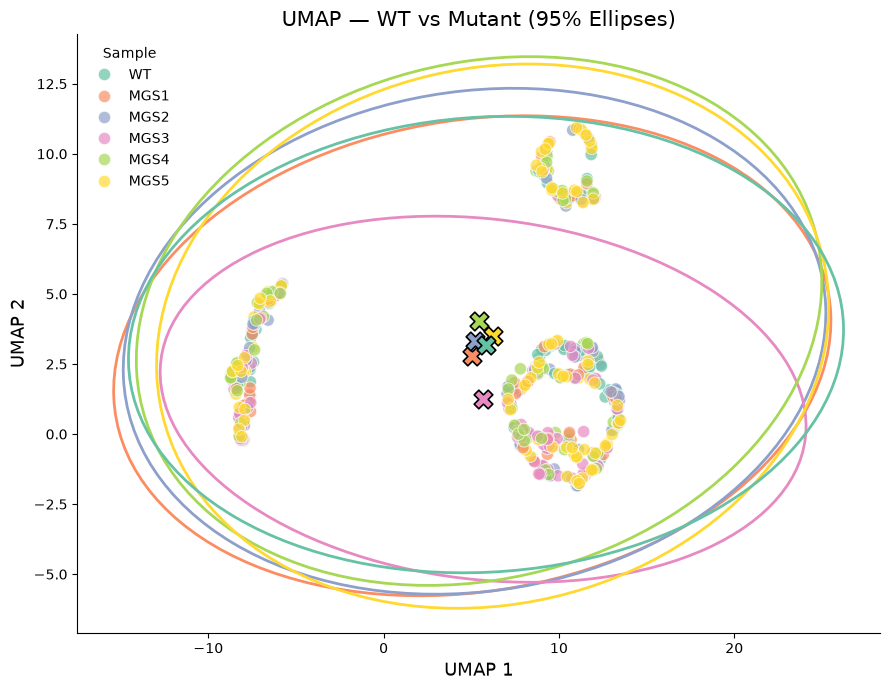

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Ellipse
from scipy.stats import chi2

def confidence_ellipse(x, y, ax, confidence=0.95, **kwargs):
    x = np.asarray(x)
    y = np.asarray(y)

    # Calculate covariance matrix
    cov = np.cov(x, y)

    # Eigenvalues and eigenvectors
    eigenvalues, eigenvectors = np.linalg.eigh(cov)

    # Sort in descending order
    order = eigenvalues.argsort()[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    # Ellipse rotation
    angle = np.degrees(
        np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0])
    )

    # 95% confidence scaling
    scale = np.sqrt(chi2.ppf(confidence, df=2))

    width, height = 2 * scale * np.sqrt(eigenvalues)

    ellipse = Ellipse(
        xy=(np.mean(x), np.mean(y)),
        width=width,
        height=height,
        angle=angle,
        fill=False,
        linewidth=2,
        **kwargs
    )

    ax.add_patch(ellipse)


# Plot
fig, ax = plt.subplots(figsize=(9, 7))

palette = dict(zip(
    umap_df["sample"].unique(),
    sns.color_palette("Set2", umap_df["sample"].nunique())
))

sns.scatterplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    hue="sample",
    palette=palette,
    s=80,
    alpha=0.7,
    edgecolor="white",
    ax=ax
)

# Add 95% ellipses
for group, data in umap_df.groupby("sample"):

    confidence_ellipse(
        data["UMAP1"],
        data["UMAP2"],
        ax,
        confidence=0.95,
        edgecolor=palette[group]
    )

    # Mark centroid
    ax.scatter(
        data["UMAP1"].mean(),
        data["UMAP2"].mean(),
        marker="X",
        s=180,
        color=palette[group],
        edgecolor="black",
        linewidth=1.2,
        zorder=5
    )

ax.set_xlabel("UMAP 1", fontsize=13)
ax.set_ylabel("UMAP 2", fontsize=13)
ax.set_title("UMAP — WT vs Mutant (95% Ellipses)", fontsize=15)

ax.legend(title="Sample", frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

In [19]:
from sklearn.manifold import trustworthiness

score = trustworthiness(
    X_scaled,
    X_umap,
    n_neighbors=10
)

print(f"UMAP trustworthiness: {score:.4f}")

UMAP trustworthiness: 0.9843


In [20]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import pdist, squareform
from skbio import DistanceMatrix
from skbio.stats.distance import permanova, permdisp

# Select features and groups
data = df[features + ["sample"]].dropna().copy()

X = data[features]
groups = data["sample"].to_numpy()

# Standardize features
X_scaled = StandardScaler().fit_transform(X)

# Euclidean distance matrix
distances = squareform(
    pdist(X_scaled, metric="euclidean")
)

dm = DistanceMatrix(distances)

# PERMANOVA
permanova_result = permanova(
    dm,
    grouping=groups,
    permutations=9999,
    seed=42
)

# PERMDISP
permdisp_result = permdisp(
    dm,
    grouping=groups,
    test="centroid",
    permutations=9999,
    seed=42
)

# Calculate R²
F = permanova_result["test statistic"]
n = len(groups)
k = len(np.unique(groups))

R2 = (F * (k - 1)) / (F * (k - 1) + (n - k))

# Results dataframe
results_df = pd.DataFrame({
    "Test": ["PERMANOVA", "PERMDISP"],
    "Statistic": [
        permanova_result["test statistic"],
        permdisp_result["test statistic"]
    ],
    "p_value": [
        permanova_result["p-value"],
        permdisp_result["p-value"]
    ],
    "R2": [R2, np.nan],
    "n": [n, n],
    "groups": [k, k]
})

display(results_df.round(4))

,Test,Statistic,p_value,R2,n,groups
0,PERMANOVA,0.8798,0.5542,0.0086,516,6
1,PERMDISP,2.5223,0.2456,NaN,516,6


/home/lopatushka/miniconda3/envs/imagej/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/lopatushka/miniconda3/envs/imagej/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/lopatushka/miniconda3/envs/imagej/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/lopatushka/miniconda3/envs/imagej/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/lopatushka/miniconda3/envs/imagej/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/lopatushka/minicond

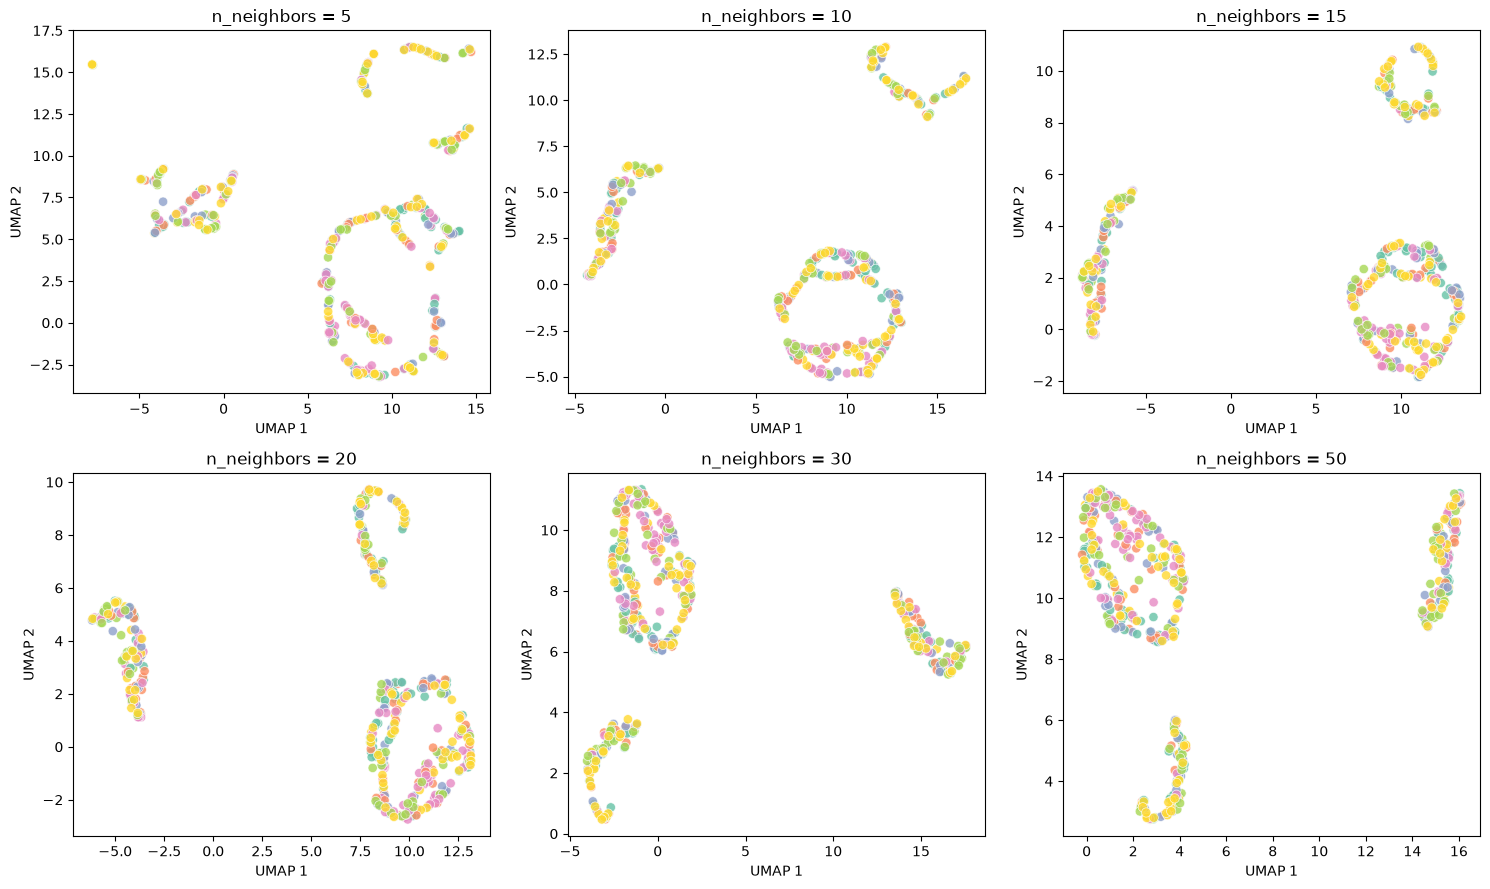

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, n in zip(axes.flat, [5, 10, 15, 20, 30, 50]):

    reducer = umap.UMAP(
        n_neighbors=n,
        min_dist=0.1,
        random_state=42
    )

    embedding = reducer.fit_transform(X_scaled)

    sns.scatterplot(
        x=embedding[:, 0],
        y=embedding[:, 1],
        hue=groups,
        palette="Set2",
        s=45,
        alpha=0.8,
        legend=False,
        ax=ax
    )

    ax.set_title(f"n_neighbors = {n}")
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")

plt.tight_layout()
plt.show()

In [26]:
groups

<StringArray>
['WT', 'MGS1', 'MGS2', 'MGS3', 'MGS4', 'MGS5']
Length: 6, dtype: str

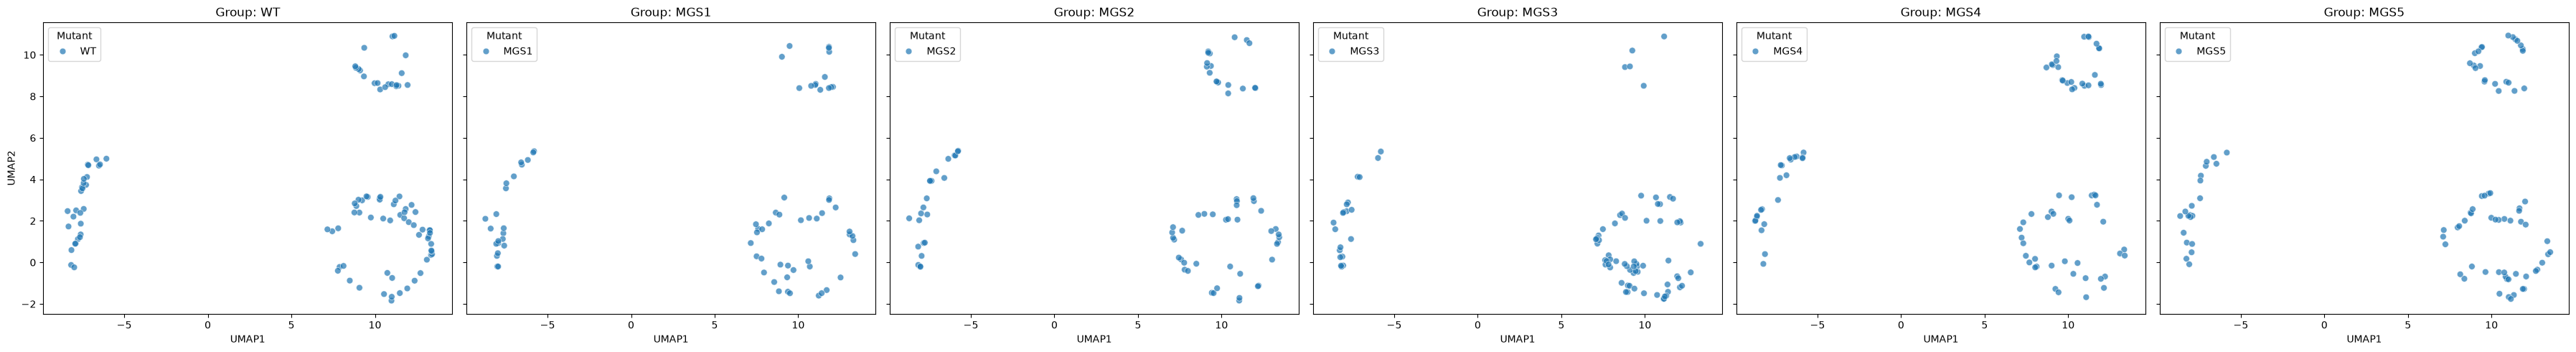

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

groups = umap_df["sample"].unique()

fig, axes = plt.subplots(
    1, len(groups),
    figsize=(6 * len(groups), 5),
    sharex=True,
    sharey=True
)

for ax, group in zip(axes, groups):
    subset = umap_df[umap_df["sample"] == group]

    sns.scatterplot(
        data=subset,
        x="UMAP1",
        y="UMAP2",
        hue="sample",
        alpha=0.7,
        s=40,
        ax=ax
    )

    ax.set_title(f"Group: {group}")
    ax.legend(title="Mutant")

plt.tight_layout()
plt.show()

In [37]:
df.groupby(["experiment", "sample"]).size()

experiment  sample
20226       MGS1      24
            MGS2      24
            MGS3      30
            MGS4      22
            MGS5      24
            WT        23
140226      MGS1      19
            MGS2      25
            MGS3      33
            MGS4      21
            MGS5      22
            WT        45
190226      MGS1      31
            MGS2      31
            MGS3      24
            MGS4      39
            MGS5      44
            WT        35
dtype: int64

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

umap_df["cluster"] = kmeans.fit_predict(
    umap_df[["UMAP1", "UMAP2"]]
)

In [40]:
umap_df.head()

,image_id,n_foci,area,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity,sample,experiment,UMAP1,UMAP2,cluster
0,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,268,6.0,2.763953,0.848528,0.875000,5.414214,45.222221,50.0,40.0,WT,20226,-7.771133,1.119161,1
1,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,277,5.0,2.523133,0.848911,0.903226,5.207107,25.250000,29.0,22.0,WT,20226,-8.156964,0.593600,1
2,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,320,5.0,2.523133,0.867934,1.000000,4.621320,31.743421,36.0,28.0,WT,20226,10.543748,-1.526916,2
3,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,341,5.0,2.523133,0.834131,1.000000,5.207107,45.625000,51.0,40.0,WT,20226,10.989454,-1.843174,2
4,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,336,4.0,2.256758,0.870250,1.000000,3.414214,34.571430,38.0,31.0,WT,20226,10.742792,-0.507493,2


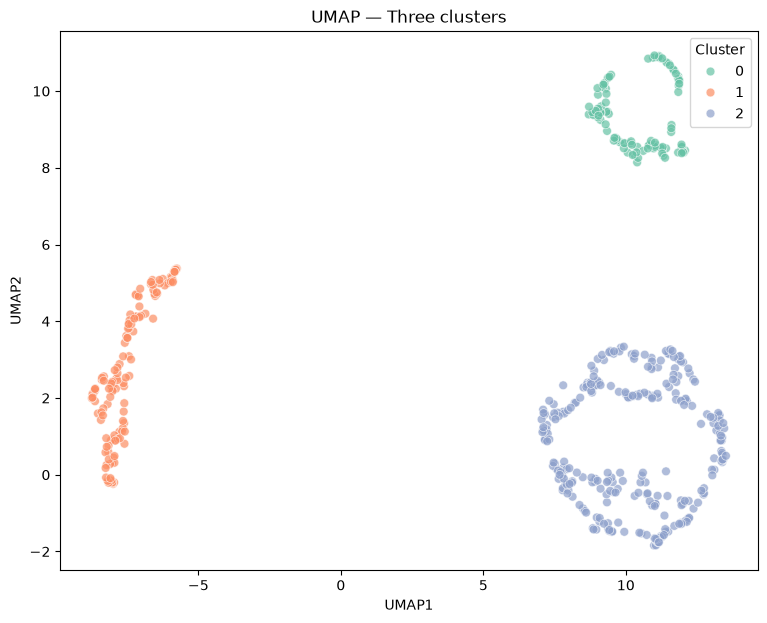

In [41]:
plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    hue="cluster",
    palette="Set2",
    s=40,
    alpha=0.7
)

plt.title("UMAP — Three clusters")
plt.legend(title="Cluster")
plt.show()

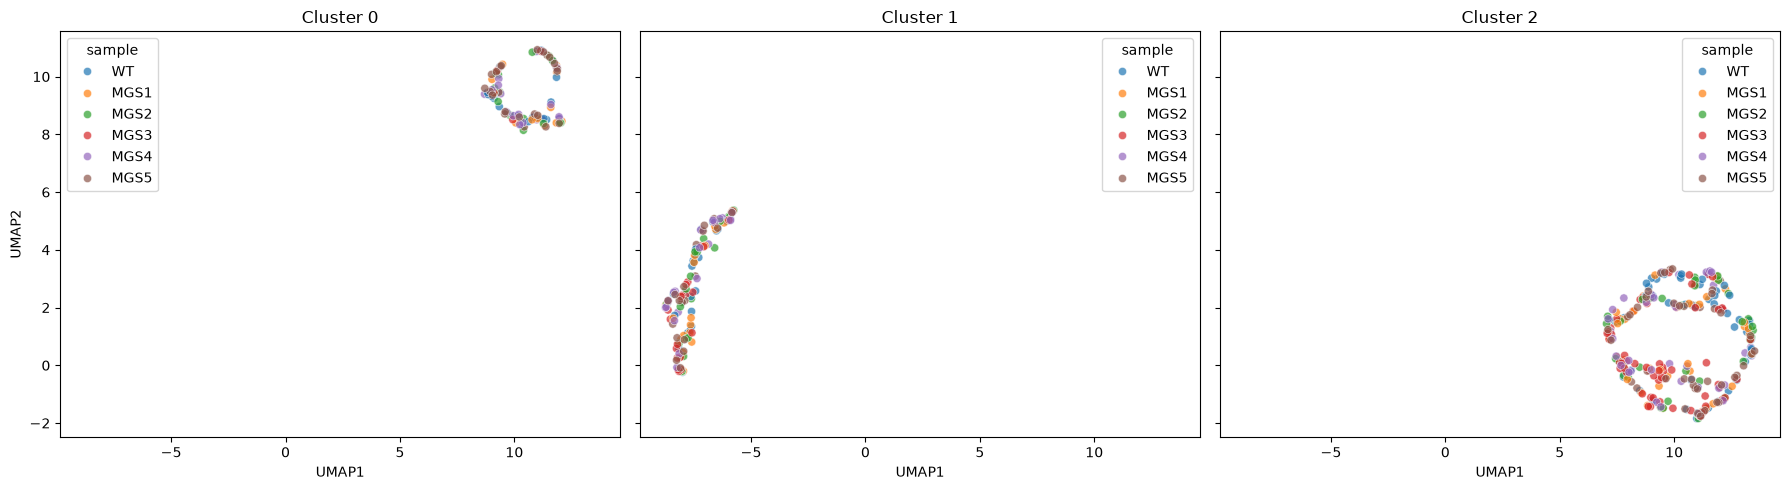

In [42]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5),
    sharex=True,
    sharey=True
)

for cluster, ax in zip(sorted(umap_df["cluster"].unique()), axes):

    subset = umap_df[umap_df["cluster"] == cluster]

    sns.scatterplot(
        data=subset,
        x="UMAP1",
        y="UMAP2",
        hue="sample",
        palette="tab10",
        alpha=0.7,
        s=35,
        ax=ax
    )

    ax.set_title(f"Cluster {cluster}")

plt.tight_layout()
plt.show()

cluster      0      1      2
sample                      
MGS1     18.92  29.73  51.35
MGS2     22.50  28.75  48.75
MGS3      5.75  22.99  71.26
MGS4     29.27  26.83  43.90
MGS5     25.56  23.33  51.11
WT       19.42  27.18  53.40


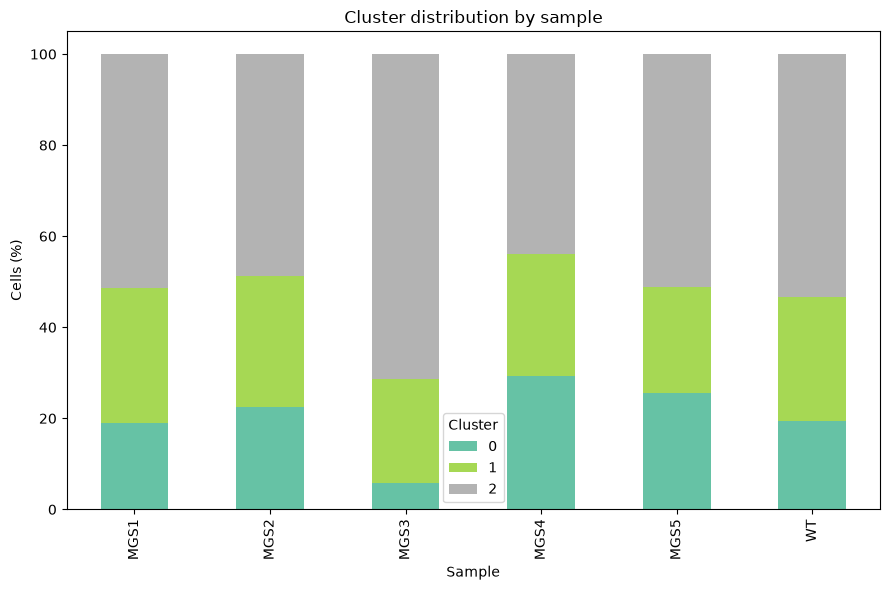

In [43]:
counts = pd.crosstab(
    umap_df["sample"],
    umap_df["cluster"]
)

proportions = counts.div(
    counts.sum(axis=1),
    axis=0
) * 100

print(proportions.round(2))

proportions.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 6),
    colormap="Set2"
)

plt.ylabel("Cells (%)")
plt.xlabel("Sample")
plt.title("Cluster distribution by sample")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [44]:
df = df.copy()
df["cluster"] = umap_df["cluster"].to_numpy()

In [45]:
from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import pdist, squareform
from skbio.stats.distance import DistanceMatrix, permanova

results = []

for cluster, subset in df.groupby("cluster"):

    subset = subset.dropna(subset=features)

    if subset["sample"].nunique() < 2:
        continue

    X = StandardScaler().fit_transform(subset[features])

    distances = squareform(
        pdist(X, metric="euclidean")
    )

    dm = DistanceMatrix(
        distances,
        ids=[str(i) for i in range(len(subset))]
    )

    result = permanova(
        dm,
        grouping=subset["sample"].to_numpy(),
        permutations=9999
    )

    results.append({
        "cluster": cluster,
        "F": result["test statistic"],
        "p_value": result["p-value"],
        "n": len(subset)
    })

results_df = pd.DataFrame(results)
print(results_df)

   cluster         F  p_value    n
0        0  0.921715   0.5347  104
1        1  1.589619   0.0705  136
2        2  1.857553   0.0310  276


In [46]:
from scipy.stats import spearmanr
import pandas as pd

results = []

for feature in features:
    for axis in ["UMAP1", "UMAP2"]:
        rho, p = spearmanr(
            df[feature],
            umap_df[axis],
            nan_policy="omit"
        )

        results.append({
            "Feature": feature,
            "Axis": axis,
            "Correlation": rho,
            "p_value": p
        })

corr_df = pd.DataFrame(results)

corr_matrix = corr_df.pivot(
    index="Feature",
    columns="Axis",
    values="Correlation"
)

print(corr_matrix)

Axis                         UMAP1     UMAP2
Feature                                     
area                     -0.604746 -0.375966
eccentricity              0.556555  0.494429
equivalent_diameter_area -0.604763 -0.376301
max_intensity            -0.711602 -0.167542
mean_intensity           -0.708868 -0.155225
min_intensity            -0.696664 -0.146506
n_foci                    0.740733 -0.271523
perimeter                -0.575559 -0.451991
solidity                  0.722095 -0.024724


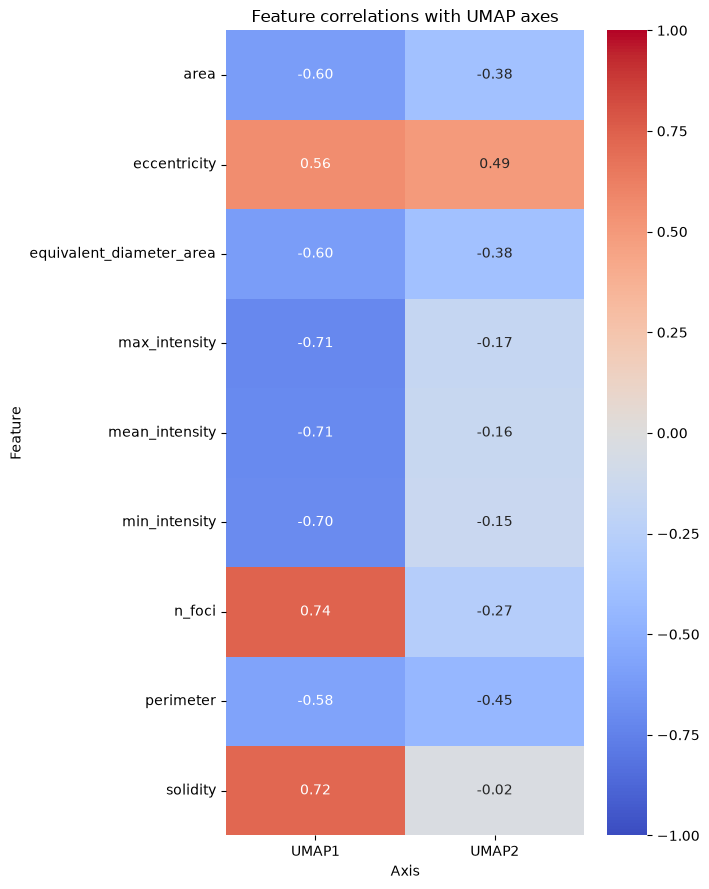

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Feature correlations with UMAP axes")
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import pdist, squareform
from skbio.stats.distance import DistanceMatrix, permanova, permdisp
from statsmodels.stats.multitest import multipletests

# Settings
cluster_id = 2
reference = "WT"
n_permutations = 9999

# Select cluster 2
df_cluster = df[df["cluster"] == cluster_id].copy()

# Remove rows with missing feature values
df_cluster = df_cluster.dropna(subset=features + ["sample"])

# Standardize features once for the entire cluster
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_cluster[features])

# Store standardized features
scaled_df = pd.DataFrame(
    X_scaled,
    index=df_cluster.index,
    columns=features
)

# Identify mutants
mutants = [
    sample for sample in df_cluster["sample"].unique()
    if sample != reference
]

results = []

for mutant in mutants:

    # Select WT and current mutant
    subset = df_cluster[
        df_cluster["sample"].isin([reference, mutant])
    ].copy()

    if subset["sample"].nunique() < 2:
        continue

    # Standardized features
    X = scaled_df.loc[subset.index].to_numpy()

    # Euclidean distance matrix
    distances = squareform(
        pdist(X, metric="euclidean")
    )

    dm = DistanceMatrix(
        distances,
        ids=[str(i) for i in range(len(subset))]
    )

    grouping = subset["sample"].to_numpy()

    # PERMANOVA
    perm = permanova(
        dm,
        grouping=grouping,
        permutations=n_permutations,
        seed=42
    )

    # PERMDISP
    disp = permdisp(
        dm,
        grouping=grouping,
        permutations=n_permutations,
        seed=42
    )

    # PERMANOVA R²
    F = perm["test statistic"]
    n = len(subset)
    k = 2

    R2 = (F * (k - 1)) / (
        F * (k - 1) + (n - k)
    )

    results.append({
        "Comparison": f"{reference} vs {mutant}",
        "n_WT": (subset["sample"] == reference).sum(),
        "n_mutant": (subset["sample"] == mutant).sum(),
        "PERMANOVA_F": F,
        "PERMANOVA_p": perm["p-value"],
        "R2": R2,
        "PERMDISP_F": disp["test statistic"],
        "PERMDISP_p": disp["p-value"]
    })

# Results
results_df = pd.DataFrame(results)

# FDR correction
if not results_df.empty:
    results_df["PERMANOVA_p_adj"] = multipletests(
        results_df["PERMANOVA_p"],
        method="fdr_bh"
    )[1]

    results_df["PERMDISP_p_adj"] = multipletests(
        results_df["PERMDISP_p"],
        method="fdr_bh"
    )[1]

print(results_df.round(4))

In [ ]:
from scipy.stats import ttest_ind
import pandas as pd
import numpy as np

results = []

for feature in features:
    wt = df.loc[df["sample"] == "WT", feature].dropna()
    mgs3 = df.loc[df["sample"] == "MGS3", feature].dropna()

    # Cohen's d
    pooled_sd = np.sqrt(
        ((len(wt)-1)*wt.var(ddof=1) +
         (len(mgs3)-1)*mgs3.var(ddof=1)) /
        (len(wt)+len(mgs3)-2)
    )

    d = (mgs3.mean() - wt.mean()) / pooled_sd if pooled_sd > 0 else np.nan

    results.append({
        "Feature": feature,
        "WT_mean": wt.mean(),
        "MGS3_mean": mgs3.mean(),
        "Cohens_d": d,
        "p_value": ttest_ind(wt, mgs3, equal_var=False).pvalue
    })

feature_results = pd.DataFrame(results)

display(
    feature_results.sort_values(
        "Cohens_d",
        key=abs,
        ascending=False
    )
)